# G110 - Detectron2: EVALUATE ONLY on dataset v2 (no training)
Uses the model already trained in the notebook **detectron2_beach2** (its `model_best.pth`). Nothing is trained here.
**Dataset:** Roboflow *G110 Beach People Final* **v2** - train/valid identical to v1; test labels completed (far-away people added, visually verified).
**New in this run:** score threshold chosen on the **validation** split (not on test), test-time augmentation (TTA) in the technique comparison,
videos saved in H.264 (they play inside Kaggle).
**Before running:** Settings -> Accelerator = GPU T4 x2, Internet = ON.
**Add Input** (right panel): (1) *Your Work -> Notebooks -> detectron2_beach2* (gives model_best.pth), (2) your dataset *g110-test-videos* (videos + waterlines.json).
Dataset download: Secret `ROBOFLOW_API_KEY`, or paste the Roboflow **v2** COCO snippet in a new cell at the very top.

In [1]:
import os, sys, subprocess, json, glob, csv, math, shutil, zipfile, collections, random
import numpy as np, cv2, torch
print('torch', torch.__version__, '| GPU:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
try:
    import detectron2
except ImportError:
    tv = '.'.join(torch.__version__.split('+')[0].split('.')[:2]); cv_ = (torch.version.cuda or '').replace('.', '')
    url = f'https://dl.fbaipublicfiles.com/detectron2/wheels/cu{cv_}/torch{tv}/index.html'
    r = subprocess.run([sys.executable, '-m', 'pip', 'install', 'detectron2', '-f', url, '-q'])
    if r.returncode != 0:
        subprocess.run([sys.executable, '-m', 'pip', 'install', 'git+https://github.com/facebookresearch/detectron2.git', '--no-build-isolation', '-q'])
    import detectron2
print('detectron2', detectron2.__version__)
subprocess.run([sys.executable, '-m', 'pip', 'install', 'pycocotools', 'seaborn', '-q'])
subprocess.run([sys.executable, '-m', 'pip', 'install', 'roboflow', '-q'])

torch 2.11.0+cu130 | GPU: True Tesla T4


ERROR: Could not find a version that satisfies the requirement detectron2 (from versions: none)
ERROR: No matching distribution found for detectron2


detectron2 0.6


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', 'roboflow', '-q'], returncode=0)

In [2]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="PASTE_YOUR_ROBOFLOW_KEY_HERE")
project = rf.workspace("mbalajis-workspace-g2gae").project("g110-beach-people-final")
version = project.version(2)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to G110-Beach-People-Final-2 in yolov8:: 100%|██████████| 9275/9275 [00:02<00:00, 4197.96it/s]


In [3]:
# ---------------- settings you may edit ----------------
MAX_ITER = 8000          # ~2-3 h on a T4. Use 12000 for a bigger dataset. Training keeps the BEST checkpoint, not the last.
EVAL_PERIOD = 500        # validation + checkpoint every N iterations
IMS_PER_BATCH = 2
SCORE_THR = 0.5          # replaced below by the threshold chosen on the VALIDATION split          # threshold for confusion matrix / counts / video
IOU_THR = 0.5
VIDEO_FPS = 3            # frames were sampled every 3 s, so 3 fps plays them 9x faster than real time
OUT = '/kaggle/working/outputs'; os.makedirs(OUT, exist_ok=True)
NAMES = ['land', 'water']
MIN_H = 15               # people shorter than this (pixels) are ignored in evaluation - same rule for all 5 models
RF_WORKSPACE, RF_PROJECT, RF_VERSION = 'mbalajis-workspace-g2gae', 'g110-beach-people-final', 2   # v2 = same train/valid as v1, test labels completed
CONT_SECONDS = 60        # continuous video: first N seconds of each test clip at real speed (None = whole clip, ~5 min, slow)
CONT_STRIDE = 2          # run the model every 2nd video frame and keep the boxes in between (halves the time)
MASKS = {'whitebay': [(1690, 0, 230, 290), (0, 1000, 1920, 80)]}   # same black boxes as the training frames (QR code + banner)

In [4]:
# ---------------- find + normalise the dataset (works with my builder OR a Roboflow COCO export) ----------------
ROOT = None
try:                                                                   # 1st choice: download the FINAL version straight from Roboflow
    from kaggle_secrets import UserSecretsClient
    from roboflow import Roboflow
    key = UserSecretsClient().get_secret('ROBOFLOW_API_KEY')
    ROOT = Roboflow(api_key=key).workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION).download('coco', location=f'/kaggle/working/rf_v{RF_VERSION}').location
except Exception as e:
    print('Roboflow download not used:', str(e)[:150])
if ROOT is None:                                                       # 2nd choice: Roboflow snippet pasted in a cell above (downloads to /kaggle/working), or an attached dataset
    for base in ('/kaggle/working',):   # NOT /kaggle/input: the old run attached there contains the v1 copy
        for dp, dn, fn in os.walk(base):
            if '_annotations.coco.json' in fn and os.path.basename(dp) == 'train': ROOT = os.path.dirname(dp); break
        if ROOT: break
if ROOT is None:                                                       # 3rd choice: team format YOLOv8 export (snippet with "yolov8") -> convert to COCO here
    from PIL import Image
    Y = None
    for base in ('/kaggle/working',):   # NOT /kaggle/input: the old run attached there contains the v1 copy
        for dp, dn, fn in os.walk(base):
            if 'data.yaml' in fn and os.path.isdir(os.path.join(dp, 'train', 'labels')): Y = dp; break
        if Y: break
    if Y:
        print('YOLOv8 export found -> converting to COCO (same boxes, only the file format changes):', Y)
        ROOT = '/kaggle/working/coco_from_yolo'
        for split in ('train', 'valid', 'test'):
            idir, ldir = os.path.join(Y, split, 'images'), os.path.join(Y, split, 'labels')
            if not os.path.isdir(idir): continue
            ims, anns = [], []
            for i, f in enumerate(sorted(os.listdir(idir))):
                p = os.path.join(idir, f); W_, H_ = Image.open(p).size
                ims.append({'id': i, 'file_name': p, 'width': W_, 'height': H_})        # absolute path: Detectron2 keeps it as is
                lp = os.path.join(ldir, os.path.splitext(f)[0] + '.txt')
                if not os.path.exists(lp): continue
                for l in open(lp):
                    q = l.split()
                    if len(q) != 5: continue
                    c, cx, cy, w, h = int(q[0]), *map(float, q[1:])                   # YOLO: class cx cy w h (0-1) -> COCO: x y w h (pixels)
                    anns.append({'id': len(anns) + 1, 'image_id': i, 'category_id': c, 'bbox': [(cx - w / 2) * W_, (cy - h / 2) * H_, w * W_, h * H_],
                                 'area': w * W_ * h * H_, 'iscrowd': 0})
            os.makedirs(os.path.join(ROOT, split), exist_ok=True)
            json.dump({'images': ims, 'annotations': anns, 'categories': [{'id': 0, 'name': '0'}, {'id': 1, 'name': '1'}]},
                      open(os.path.join(ROOT, split, '_annotations.coco.json'), 'w'))
            print(f'  {split}: {len(ims)} images, {len(anns)} boxes converted')
assert ROOT, 'dataset not found - paste the Roboflow v2 snippet (yolov8 or coco) in a cell above, or add the ROBOFLOW_API_KEY secret'
print('dataset root:', ROOT)
assert '/kaggle/input' not in ROOT, 'wrong dataset (old v1 copy) - download Roboflow v2'
os.makedirs('/kaggle/working/coco_fixed', exist_ok=True)
def to_id(n):
    n = str(n).strip().lower(); return 0 if n in ('0', 'land') else 1 if n in ('1', 'water') else None
def norm_coco(split):
    d = json.load(open(os.path.join(ROOT, split, '_annotations.coco.json')))
    m = {c['id']: to_id(c['name']) for c in d['categories']}            # drops Roboflow's dummy category automatically
    anns = []
    for a in d['annotations']:
        if m.get(a['category_id']) is None or a['bbox'][2] < 1 or a['bbox'][3] < 1: continue
        small = a['bbox'][3] < MIN_H and split == 'test'                # 15 px rule: ignore region, neither a hit nor a miss
        anns.append(dict(a, category_id=m[a['category_id']], iscrowd=1 if small else 0))
    for i, a in enumerate(anns): a['id'] = i + 1
    out = {'images': d['images'], 'annotations': anns, 'categories': [{'id': 0, 'name': 'land'}, {'id': 1, 'name': 'water'}]}
    p = f'/kaggle/working/coco_fixed/{split}.json'; json.dump(out, open(p, 'w'))
    c = collections.Counter(a['category_id'] for a in anns)
    print(f'{split:6s} images={len(out["images"]):5d} land={c[0]:6d} water={c[1]:6d}'); return p
JS = {s: norm_coco(s) for s in ('train', 'valid', 'test') if os.path.exists(os.path.join(ROOT, s, '_annotations.coco.json'))}
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.data.datasets import register_coco_instances
for s, p in JS.items():
    register_coco_instances(f'g110_{s}', {}, p, os.path.join(ROOT, s)); MetadataCatalog.get(f'g110_{s}').thing_classes = NAMES
n_train = len(json.load(open(JS['train']))['images']); print('train images:', n_train)
n_test = len(json.load(open(JS['test']))['images']); print('test images:', n_test, '(expected 399)')
print('test boxes ignored by the 15 px rule:', sum(a['iscrowd'] for a in json.load(open(JS['test']))['annotations']))

Roboflow download not used: Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 144825650 and label ROBOFLOW_API_KEY.'], 'error': {'c
YOLOv8 export found -> converting to COCO (same boxes, only the file format changes): /kaggle/working/G110-Beach-People-Final-2
  train: 3454 images, 132027 boxes converted
  valid: 782 images, 31443 boxes converted
  test: 399 images, 13214 boxes converted
dataset root: /kaggle/working/coco_from_yolo
train  images= 3454 land= 57634 water= 74393
valid  images=  782 land= 13558 water= 17885
test   images=  399 land=  4559 water=  8655
train images: 3454
test images: 399 (expected 399)
test boxes ignored by the 15 px rule: 1296


In [5]:
# ---------------- config + trainer ----------------
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.engine import DefaultTrainer, hooks
from detectron2.evaluation import COCOEvaluator
CFGFILE = 'COCO-Detection/faster_rcnn_R_101_FPN_3x.yaml'
cfg = get_cfg(); cfg.merge_from_file(model_zoo.get_config_file(CFGFILE)); cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CFGFILE)
cfg.DATASETS.TRAIN = ('g110_train',); cfg.DATASETS.TEST = ('g110_valid',) if 'valid' in JS else ()
cfg.DATALOADER.NUM_WORKERS = 4; cfg.DATALOADER.FILTER_EMPTY_ANNOTATIONS = False
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 2; cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 256; cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.05
cfg.MODEL.ANCHOR_GENERATOR.SIZES = [[8], [16], [32], [64], [128]]            # small anchors for small people (3 aspect ratios kept so pretrained RPN weights still load)
cfg.INPUT.MIN_SIZE_TRAIN = (1080, 1200, 1320); cfg.INPUT.MAX_SIZE_TRAIN = 2400
cfg.INPUT.MIN_SIZE_TEST = 1320; cfg.INPUT.MAX_SIZE_TEST = 2400                # NOT 640: small swimmers need resolution
cfg.SOLVER.IMS_PER_BATCH = IMS_PER_BATCH; cfg.SOLVER.BASE_LR = 0.0025; cfg.SOLVER.AMP.ENABLED = True
cfg.SOLVER.MAX_ITER = MAX_ITER; cfg.SOLVER.STEPS = (int(0.7 * MAX_ITER), int(0.9 * MAX_ITER)); cfg.SOLVER.GAMMA = 0.1; cfg.SOLVER.WARMUP_ITERS = 500
cfg.SOLVER.CHECKPOINT_PERIOD = EVAL_PERIOD; cfg.TEST.EVAL_PERIOD = EVAL_PERIOD if 'valid' in JS else 0; cfg.TEST.DETECTIONS_PER_IMAGE = 300
cfg.OUTPUT_DIR = os.path.join(OUT, 'd2'); os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)
class Trainer(DefaultTrainer):
    @classmethod
    def build_evaluator(cls, cfg, dataset_name): return COCOEvaluator(dataset_name, output_dir=os.path.join(cfg.OUTPUT_DIR, 'eval_' + dataset_name))
    def build_hooks(self):
        h = super().build_hooks()
        if self.cfg.TEST.EVAL_PERIOD > 0: h.insert(-1, hooks.BestCheckpointer(self.cfg.TEST.EVAL_PERIOD, self.checkpointer, 'bbox/AP50', 'max', file_prefix='model_best'))
        return h
open(os.path.join(OUT, 'config_used.yaml'), 'w').write(cfg.dump())
print('iterations:', MAX_ITER, '| ~epochs:', round(MAX_ITER * IMS_PER_BATCH / max(n_train, 1), 1))

pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.


iterations: 8000 | ~epochs: 4.6


In [6]:
# ---------------- LOAD the trained model (no training) ----------------
import shutil
W_BEST = sorted(glob.glob('/kaggle/input/**/model_best.pth', recursive=True))
assert W_BEST, 'model_best.pth not found: Add Input -> Your Work -> Notebooks -> detectron2_beach2'
shutil.copy2(W_BEST[0], os.path.join(cfg.OUTPUT_DIR, 'model_best.pth')); print('model:', W_BEST[0])
M_JS = [p for p in glob.glob('/kaggle/input/**/metrics.json', recursive=True) if os.path.dirname(p) == os.path.dirname(W_BEST[0])] or sorted(glob.glob('/kaggle/input/**/d2/metrics.json', recursive=True))
assert M_JS, 'metrics.json of the training run not found next to model_best.pth'
shutil.copy2(M_JS[0], os.path.join(cfg.OUTPUT_DIR, 'metrics.json')); print('training log:', M_JS[0])

model: /kaggle/input/notebooks/mbalajisakthivel/detectron2-beach2/outputs/d2/model_best.pth
training log: /kaggle/input/notebooks/mbalajisakthivel/detectron2-beach2/outputs/d2/metrics.json


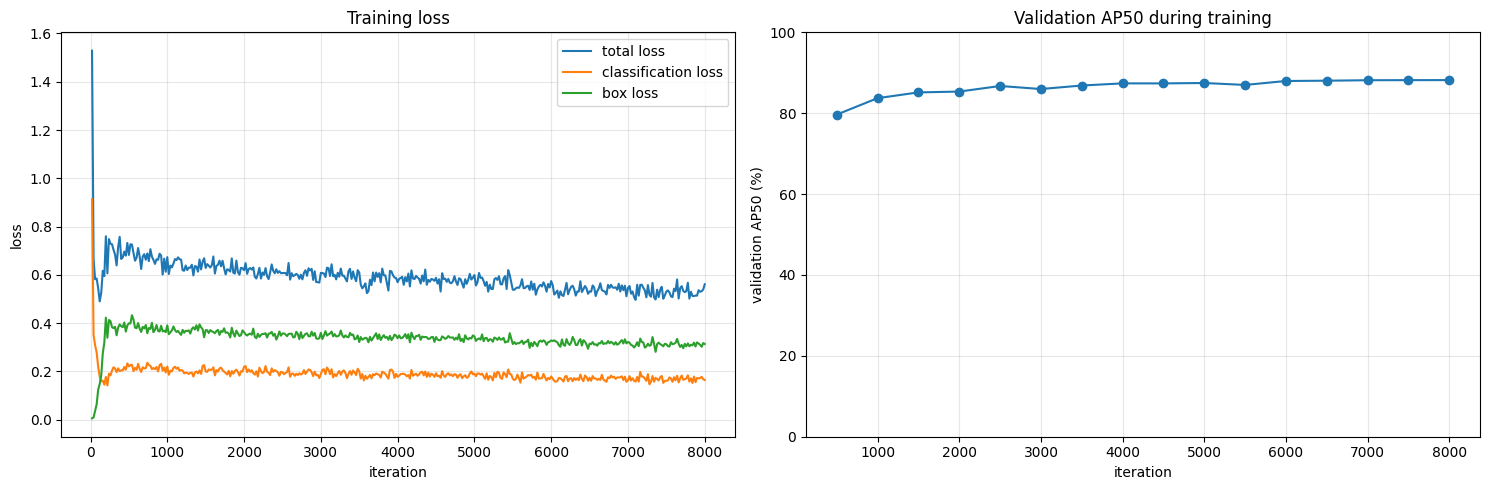

best validation AP50: 88.19 at iteration 8000


In [7]:
# ---------------- training curves ----------------
import matplotlib; import matplotlib.pyplot as plt
rows = [json.loads(l) for l in open(os.path.join(cfg.OUTPUT_DIR, 'metrics.json')) if l.strip()]
it = [r['iteration'] for r in rows if 'total_loss' in r]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for k, lab in (('total_loss', 'total loss'), ('loss_cls', 'classification loss'), ('loss_box_reg', 'box loss')):
    ys = [r[k] for r in rows if k in r]
    if ys: ax[0].plot(it[:len(ys)], ys, label=lab)
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('loss'); ax[0].set_title('Training loss'); ax[0].legend(); ax[0].grid(alpha=.3)
vi = [(r['iteration'], r['bbox/AP50']) for r in rows if 'bbox/AP50' in r]
if vi: ax[1].plot(*zip(*vi), marker='o'); ax[1].set_ylim(0, 100)
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('validation AP50 (%)'); ax[1].set_title('Validation AP50 during training'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT, '01_training_curves.png'), dpi=200); plt.show()
if vi: print('best validation AP50: %.2f at iteration %d' % (max(v for _, v in vi), max(vi, key=lambda x: x[1])[0]))

In [8]:
# ---------------- predict on the TEST set with the best checkpoint ----------------
from detectron2.engine import DefaultPredictor
best = os.path.join(cfg.OUTPUT_DIR, 'model_best.pth'); cfg.MODEL.WEIGHTS = best if os.path.exists(best) else os.path.join(cfg.OUTPUT_DIR, 'model_final.pth')
print('using weights:', cfg.MODEL.WEIGHTS)
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.05
predictor = DefaultPredictor(cfg)
def arrs(inst):                                                       # model output -> arrays, dropping boxes shorter than MIN_H (15 px rule)
    b = inst.pred_boxes.tensor.numpy(); s = inst.scores.numpy(); c = inst.pred_classes.numpy(); k = (b[:, 3] - b[:, 1]) >= MIN_H
    return b[k], s[k], c[k]
def beach_of(fn): return os.path.basename(fn).split('_')[0]
test_dicts = DatasetCatalog.get('g110_test'); preds = {}; dets = []
import time; t0 = time.time()
for d in test_dicts:
    im = cv2.imread(d['file_name']); inst = predictor(im)['instances'].to('cpu')
    b, s, c = arrs(inst); preds[d['image_id']] = (b, s, c)
    for bb, ss, cc in zip(b, s, c): dets.append({'image_id': d['image_id'], 'category_id': int(cc), 'bbox': [float(bb[0]), float(bb[1]), float(bb[2] - bb[0]), float(bb[3] - bb[1])], 'score': float(ss)})
json.dump(dets, open(os.path.join(OUT, 'test_detections.json'), 'w')); print('test images:', len(test_dicts), '| detections:', len(dets))
FPS_MODEL = len(test_dicts) / (time.time() - t0); print('speed: %.2f frames/s at test size %d' % (FPS_MODEL, cfg.INPUT.MIN_SIZE_TEST))

using weights: /kaggle/working/outputs/d2/model_best.pth



Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
W1113 15:53:44.426000 22 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


test images: 399 | detections: 21456
speed: 1.30 frames/s at test size 1320


In [9]:
# ---------------- choose the score threshold on the VALIDATION split (fair: test is not used to pick it) ----------------
def _iou(a, b):
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1]); ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    return inter / (((a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]))[:, None] + ((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]))[None, :] - inter + 1e-9)
val_dicts = DatasetCatalog.get('g110_valid'); VP = {}; VG = {}
for d in val_dicts:
    VP[d['image_id']] = arrs(predictor(cv2.imread(d['file_name']))['instances'].to('cpu'))
    VG[d['image_id']] = [(x, y, x + w, y + h, a['category_id']) for a in d['annotations'] for x, y, w, h in [a['bbox']] if h >= MIN_H]   # COCO dicts: bbox = x, y, w, h (XYWH_ABS)
def f1_at(thr):
    tp = np.zeros(2); fp = np.zeros(2); fn = np.zeros(2)
    for i, (b, s, c) in VP.items():
        k = s >= thr; b, s, c = b[k], s[k], c[k]; o = np.argsort(-s); b, c = b[o], c[o]
        G = np.array([g[:4] for g in VG[i]], float).reshape(-1, 4); gc = [g[4] for g in VG[i]]; used = set()
        M = _iou(b, G) if len(b) and len(G) else np.zeros((len(b), len(G)))
        for p in range(len(b)):
            j = max((jj for jj in range(len(G)) if jj not in used and M[p, jj] >= IOU_THR), key=lambda jj: M[p, jj], default=-1)
            if j >= 0 and gc[j] == c[p]: used.add(j); tp[c[p]] += 1
            elif j >= 0: used.add(j); fp[c[p]] += 1; fn[gc[j]] += 1
            else: fp[c[p]] += 1
        for j in range(len(G)):
            if j not in used: fn[gc[j]] += 1
    f = 2 * tp / np.maximum(2 * tp + fp + fn, 1); return 100 * f
grid = [round(t, 2) for t in np.arange(0.30, 0.91, 0.05)]; vs = [(t, *f1_at(t)) for t in grid]
for t, fl, fw in vs: print(f'validation  thr {t:.2f}:  F1 land {fl:.2f}  F1 water {fw:.2f}  mean {(fl + fw) / 2:.2f}')
SCORE_THR = max(vs, key=lambda r: r[1] + r[2])[0]
print('==> SCORE_THR chosen on validation =', SCORE_THR, '(used for confusion matrices, counts and videos below)')
with open(os.path.join(OUT, 'threshold_choice_validation.csv'), 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['score_thr', 'val_F1_land', 'val_F1_water']); w.writerows([[t, round(a, 2), round(b, 2)] for t, a, b in vs])


Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.



validation  thr 0.30:  F1 land 76.60  F1 water 85.80  mean 81.20
validation  thr 0.35:  F1 land 77.59  F1 water 86.09  mean 81.84
validation  thr 0.40:  F1 land 78.36  F1 water 86.35  mean 82.36
validation  thr 0.45:  F1 land 78.87  F1 water 86.57  mean 82.72
validation  thr 0.50:  F1 land 79.23  F1 water 86.81  mean 83.02
validation  thr 0.55:  F1 land 79.31  F1 water 86.94  mean 83.12
validation  thr 0.60:  F1 land 79.35  F1 water 87.00  mean 83.18
validation  thr 0.65:  F1 land 79.22  F1 water 86.93  mean 83.08
validation  thr 0.70:  F1 land 78.56  F1 water 86.84  mean 82.70
validation  thr 0.75:  F1 land 77.69  F1 water 86.57  mean 82.13
validation  thr 0.80:  F1 land 76.42  F1 water 86.27  mean 81.35
validation  thr 0.85:  F1 land 74.19  F1 water 85.54  mean 79.86
validation  thr 0.90:  F1 land 70.20  F1 water 84.10  mean 77.15
==> SCORE_THR chosen on validation = 0.6 (used for confusion matrices, counts and videos below)


In [10]:
# ---------------- COCO metrics: mAP@50, mAP@50:95, per-class AP / AR ----------------
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import contextlib, io
gt = COCO(JS['test']); dt = gt.loadRes(dets) if dets else None
def coco_run(img_ids=None, cat_ids=None, quiet=True):
    E = COCOeval(gt, dt, 'bbox')
    if img_ids is not None: E.params.imgIds = list(img_ids)
    if cat_ids is not None: E.params.catIds = list(cat_ids)
    with contextlib.redirect_stdout(io.StringIO()) if quiet else contextlib.nullcontext(): E.evaluate(); E.accumulate(); E.summarize()
    return E
E_all = coco_run(); st = E_all.stats
res = {'mAP@50': 100 * st[1], 'mAP@50:95': 100 * st[0], 'AR@100': 100 * st[8]}
for k, n in enumerate(NAMES):
    Ek = coco_run(cat_ids=[k]); res[f'AP50 {n}'] = 100 * Ek.stats[1]; res[f'AP50:95 {n}'] = 100 * Ek.stats[0]; res[f'AR {n}'] = 100 * Ek.stats[8]
beach_ids = collections.defaultdict(list)
for d in test_dicts: beach_ids[beach_of(d['file_name'])].append(d['image_id'])
for bch, ids in sorted(beach_ids.items()):                          # per beach: White Bay (crowded) vs Sunny Isles (less crowded)
    Eb = coco_run(img_ids=ids); res[f'{bch} mAP@50'] = 100 * Eb.stats[1]; res[f'{bch} mAP@50:95'] = 100 * Eb.stats[0]
    for k, n in enumerate(NAMES): res[f'{bch} AP50 {n}'] = 100 * coco_run(img_ids=ids, cat_ids=[k]).stats[1]
res['speed fps'] = FPS_MODEL
for k, v in res.items(): print(f'{k:26s}: ' + ('n/a (no such people)' if v < 0 else f'{v:6.2f}' + ('' if 'fps' in k else '%')))
json.dump(res, open(os.path.join(OUT, 'metrics_coco.json'), 'w'), indent=2)

loading annotations into memory...
Done (t=0.03s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.03s)
creating index...
index created!
mAP@50                    :  79.24%
mAP@50:95                 :  41.87%
AR@100                    :  56.42%
AP50 land                 :  83.89%
AP50:95 land              :  53.39%
AR land                   :  68.22%
AP50 water                :  74.59%
AP50:95 water             :  30.34%
AR water                  :  44.62%
sunnyisles mAP@50         :  69.16%
sunnyisles mAP@50:95      :  32.06%
sunnyisles AP50 land      :  73.54%
sunnyisles AP50 water     :  64.78%
whitebay mAP@50           :  81.78%
whitebay mAP@50:95        :  45.61%
whitebay AP50 land        :  87.33%
whitebay AP50 water       :  76.23%
speed fps                 :   1.30


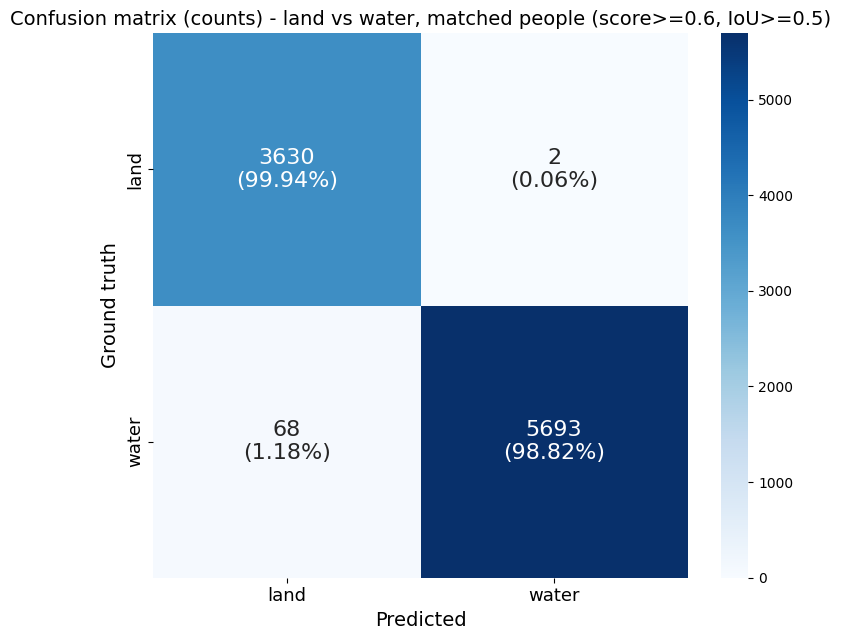

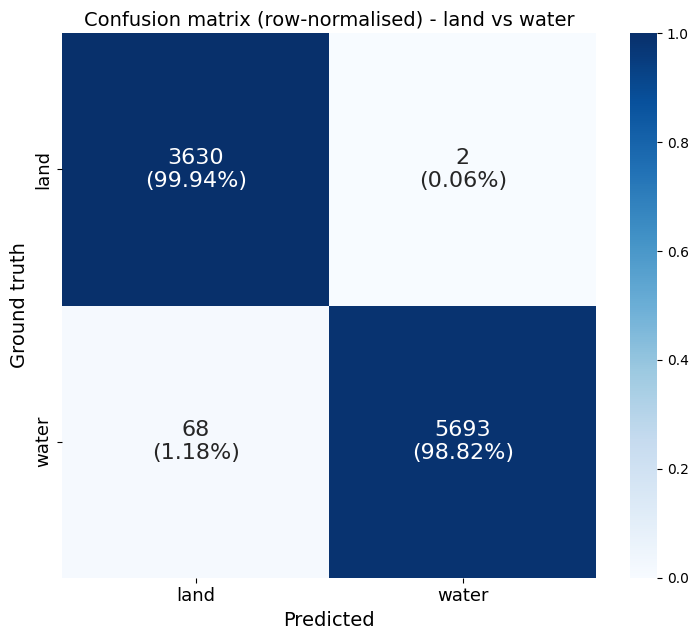

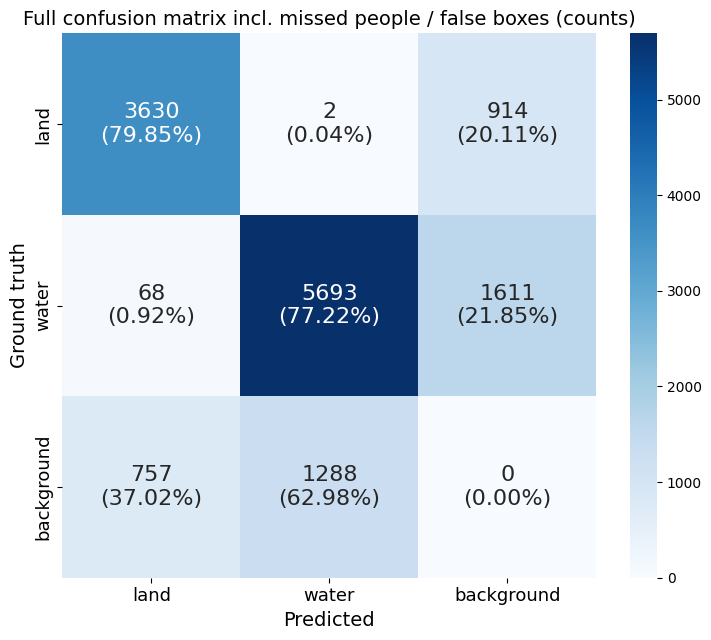

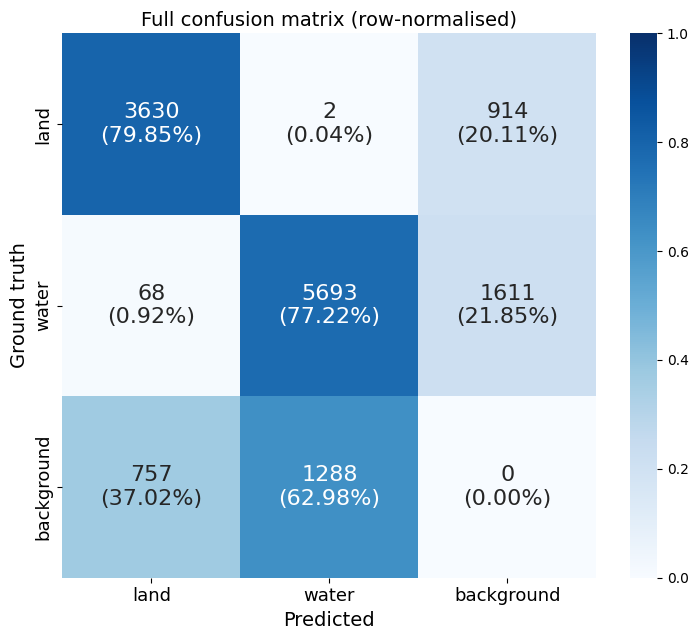

land   precision=81.48%  recall(sensitivity)=79.85%  F1=80.66%  mean IoU=84.58%  (GT people: 4546)
water  precision=81.53%  recall(sensitivity)=77.22%  F1=79.32%  mean IoU=74.84%  (GT people: 7372)
weighted F1: 79.83%
missed people (GT but no box): 2525 | false boxes (box but no GT person): 2045 | land<->water mix-ups: 70


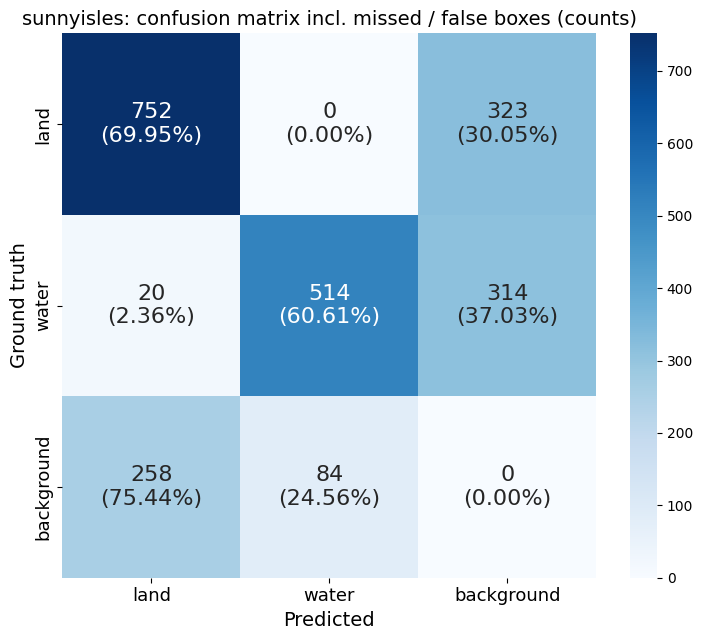

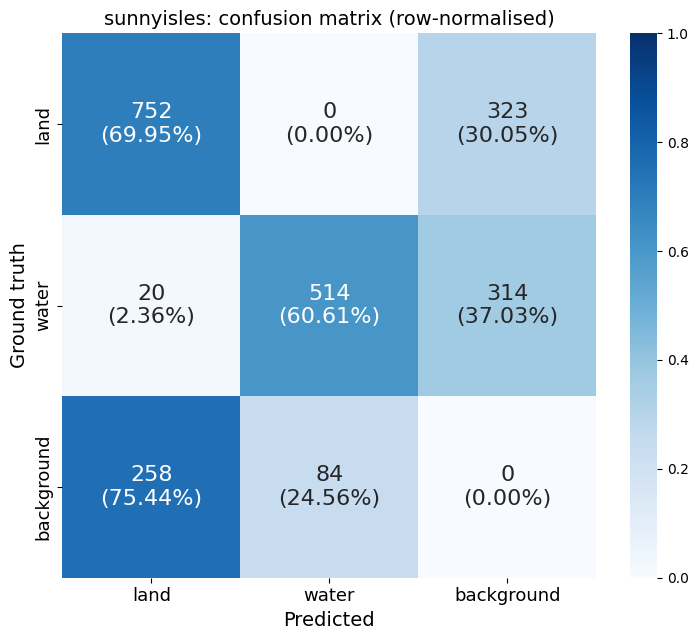

sunnyisles land   precision=73.01%  recall=69.95%  F1=71.45%
sunnyisles water  precision=85.95%  recall=60.61%  F1=71.09%


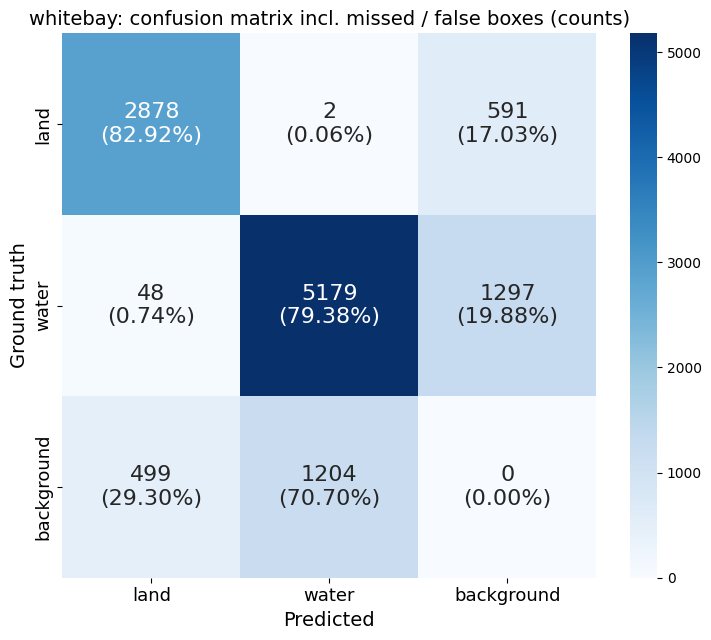

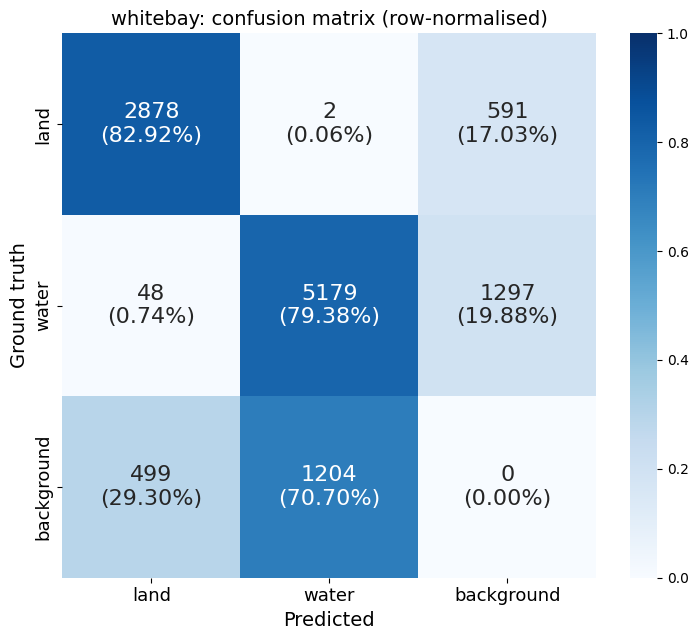

whitebay   land   precision=84.03%  recall=82.92%  F1=83.47%
whitebay   water  precision=81.11%  recall=79.38%  F1=80.24%


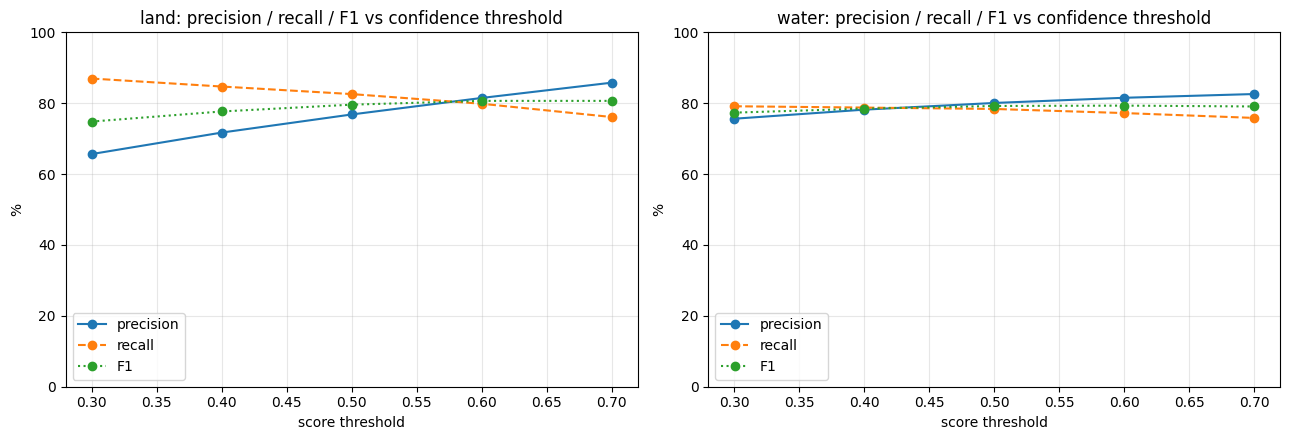

In [11]:
# ---------------- confusion matrix (raw + normalised) and per-class precision / recall / F1 / IoU ----------------
import seaborn as sns
def iou_mat(a, b):
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1]); ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None); aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); bb = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + bb[None, :] - inter + 1e-9)
gt_boxes = collections.defaultdict(list)
for a in gt.dataset['annotations']:
    if a.get('iscrowd'): continue                                       # 15 px rule
    x, y, w, h = a['bbox']; gt_boxes[a['image_id']].append((x, y, x + w, y + h, a['category_id']))
def confusion(thr=SCORE_THR, iou_thr=IOU_THR, img_ids=None, P=None):
    P = preds if P is None else P
    cm = np.zeros((3, 3), dtype=int); ious = {0: [], 1: []}                 # rows: true land/water/background ; cols: predicted land/water/background
    for iid in (img_ids if img_ids is not None else [d['image_id'] for d in test_dicts]):
        G = np.array([g[:4] for g in gt_boxes[iid]], dtype=float).reshape(-1, 4); gc = [g[4] for g in gt_boxes[iid]]
        b, s, c = P[iid]; keep = s >= thr; b, s, c = b[keep], s[keep], c[keep]; order = np.argsort(-s); b, c = b[order], c[order]
        used = set(); M = iou_mat(b, G) if len(b) and len(G) else np.zeros((len(b), len(G)))
        for i in range(len(b)):
            j = -1; best = iou_thr
            for jj in range(len(G)):
                if jj not in used and M[i, jj] >= best: best = M[i, jj]; j = jj
            if j >= 0: used.add(j); cm[gc[j], c[i]] += 1; ious[gc[j]].append(M[i, j])
            else: cm[2, c[i]] += 1                                            # false positive (predicted a person where GT has none)
        for j in range(len(G)):
            if j not in used: cm[gc[j], 2] += 1                               # missed person
    return cm, ious
def prf(cm, ious):
    out = {}
    for k, n in enumerate(NAMES):
        tp = cm[k, k]; fp = cm[:, k].sum() - tp; fn = cm[k, :].sum() - tp
        p = tp / (tp + fp) if tp + fp else 0.0; r = tp / (tp + fn) if tp + fn else 0.0; f = 2 * p * r / (p + r) if p + r else 0.0
        out[n] = dict(precision=100 * p, recall=100 * r, f1=100 * f, mean_iou=100 * (np.mean(ious[k]) if ious[k] else 0.0), support=int(cm[k, :].sum()))
    tot = sum(o['support'] for o in out.values()); out['weighted_F1'] = sum(o['f1'] * o['support'] for o in out.values() if isinstance(o, dict)) / max(tot, 1)
    return out
def heat(mat, labels_r, labels_c, title, fname, normalise):
    fig, ax = plt.subplots(figsize=(7.5, 6.5)); denom = mat.sum(axis=1, keepdims=True).astype(float); denom[denom == 0] = 1
    pct = 100 * mat / denom; ann = np.array([[f'{mat[i, j]}\n({pct[i, j]:.2f}%)' for j in range(mat.shape[1])] for i in range(mat.shape[0])])
    sns.heatmap(pct / 100 if normalise else mat, annot=ann, fmt='', cmap='Blues', cbar=True, xticklabels=labels_c, yticklabels=labels_r, annot_kws={'size': 16}, ax=ax, vmin=0, vmax=1 if normalise else None)
    ax.set_xlabel('Predicted', fontsize=14); ax.set_ylabel('Ground truth', fontsize=14); ax.set_title(title, fontsize=14); ax.tick_params(labelsize=13)
    plt.tight_layout(); plt.savefig(os.path.join(OUT, fname), dpi=220); plt.show()
cm, ious = confusion(); stats = prf(cm, ious)
heat(cm[:2, :2], NAMES, NAMES, f'Confusion matrix (counts) - land vs water, matched people (score>={SCORE_THR}, IoU>={IOU_THR})', '02_confusion_raw_2x2.png', False)
heat(cm[:2, :2], NAMES, NAMES, 'Confusion matrix (row-normalised) - land vs water', '03_confusion_normalised_2x2.png', True)
heat(cm, NAMES + ['background'], NAMES + ['background'], 'Full confusion matrix incl. missed people / false boxes (counts)', '04_confusion_full_3x3.png', False)
heat(cm, NAMES + ['background'], NAMES + ['background'], 'Full confusion matrix (row-normalised)', '05_confusion_full_3x3_normalised.png', True)
for n in NAMES: print(f"{n:6s} precision={stats[n]['precision']:.2f}%  recall(sensitivity)={stats[n]['recall']:.2f}%  F1={stats[n]['f1']:.2f}%  mean IoU={stats[n]['mean_iou']:.2f}%  (GT people: {stats[n]['support']})")
print('weighted F1: %.2f%%' % stats['weighted_F1'])
print('missed people (GT but no box):', cm[0, 2] + cm[1, 2], '| false boxes (box but no GT person):', cm[2, 0] + cm[2, 1], '| land<->water mix-ups:', cm[0, 1] + cm[1, 0])
sweep = []
for thr in (0.3, 0.4, 0.5, 0.6, 0.7):
    c_, i_ = confusion(thr); s_ = prf(c_, i_); sweep.append([thr] + [round(s_[n][m], 2) for n in NAMES for m in ('precision', 'recall', 'f1')])
with open(os.path.join(OUT, 'threshold_sweep.csv'), 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['score_thr'] + [f'{n}_{m}' for n in NAMES for m in ('precision', 'recall', 'f1')]); w.writerows(sweep)
json.dump({'confusion_3x3_rows_true_cols_pred_land_water_bg': cm.tolist(), 'per_class': stats}, open(os.path.join(OUT, 'metrics_confusion.json'), 'w'), indent=2)
# per-beach confusion matrices
per_beach = {}
for bch, ids in sorted(beach_ids.items()):
    cb, ib = confusion(img_ids=ids); per_beach[bch] = {'confusion_3x3': cb.tolist(), 'per_class': prf(cb, ib)}
    heat(cb, NAMES + ['background'], NAMES + ['background'], f'{bch}: confusion matrix incl. missed / false boxes (counts)', f'02b_confusion_{bch}.png', False)
    heat(cb, NAMES + ['background'], NAMES + ['background'], f'{bch}: confusion matrix (row-normalised)', f'02c_confusion_{bch}_normalised.png', True)
    for n in NAMES: print(f"{bch:10s} {n:6s} precision={per_beach[bch]['per_class'][n]['precision']:.2f}%  recall={per_beach[bch]['per_class'][n]['recall']:.2f}%  F1={per_beach[bch]['per_class'][n]['f1']:.2f}%")
json.dump(per_beach, open(os.path.join(OUT, 'metrics_per_beach.json'), 'w'), indent=2)
# precision / recall / F1 against the confidence threshold (picture of threshold_sweep.csv)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5)); th = [r[0] for r in sweep]
for k, n in enumerate(NAMES):
    for m, (lab, ls) in enumerate((('precision', '-'), ('recall', '--'), ('F1', ':'))): ax[k].plot(th, [r[1 + 3 * k + m] for r in sweep], ls, marker='o', label=lab)
    ax[k].set_title(f'{n}: precision / recall / F1 vs confidence threshold'); ax[k].set_xlabel('score threshold'); ax[k].set_ylabel('%'); ax[k].set_ylim(0, 100); ax[k].grid(alpha=.3); ax[k].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT, '06b_threshold_sweep.png'), dpi=200); plt.show()

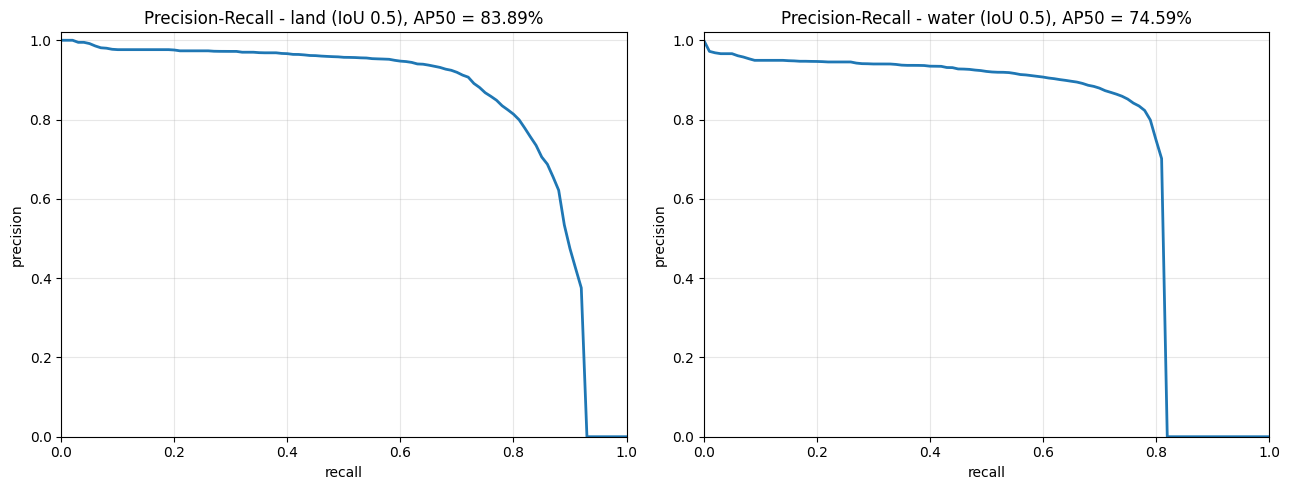

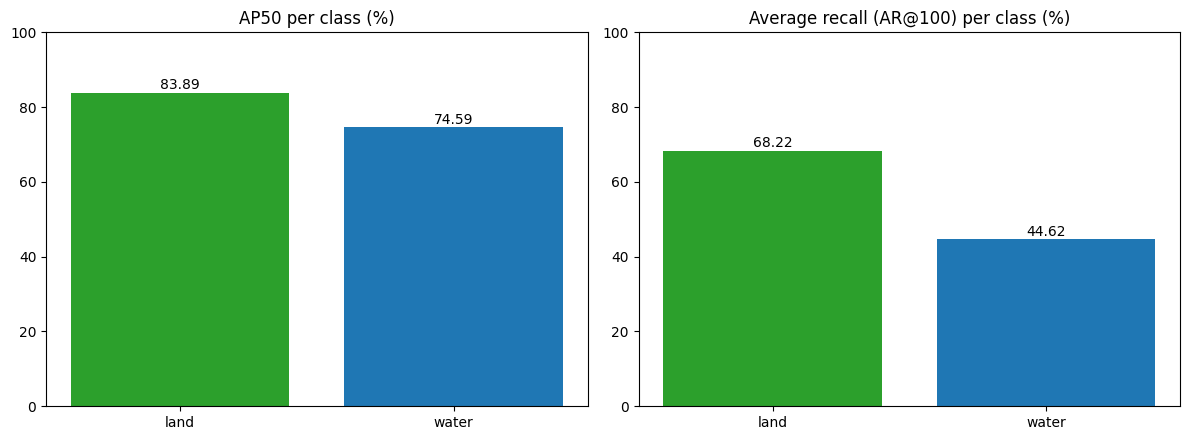

In [12]:
# ---------------- PR curves, per-class AP/AR bars ----------------
P = E_all.eval['precision']; rec = np.linspace(0, 1, 101)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k, n in enumerate(NAMES):
    pr = P[0, :, k, 0, 2]; ax[k].plot(rec, np.where(pr > -1, pr, 0), lw=2); ax[k].set_xlim(0, 1); ax[k].set_ylim(0, 1.02)
    ax[k].set_title(f'Precision-Recall - {n} (IoU 0.5), AP50 = {res["AP50 " + n]:.2f}%'); ax[k].set_xlabel('recall'); ax[k].set_ylabel('precision'); ax[k].grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT, '06_pr_curves.png'), dpi=200); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5)); x = np.arange(2)
ax[0].bar(x, [res['AP50 land'], res['AP50 water']], color=['#2ca02c', '#1f77b4']); ax[0].set_xticks(x); ax[0].set_xticklabels(NAMES); ax[0].set_ylim(0, 100); ax[0].set_title('AP50 per class (%)')
ax[1].bar(x, [res['AR land'], res['AR water']], color=['#2ca02c', '#1f77b4']); ax[1].set_xticks(x); ax[1].set_xticklabels(NAMES); ax[1].set_ylim(0, 100); ax[1].set_title('Average recall (AR@100) per class (%)')
for a in ax:
    for rect in a.patches: a.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 1, f'{rect.get_height():.2f}', ha='center')
plt.tight_layout(); plt.savefig(os.path.join(OUT, '07_per_class_ap_ar.png'), dpi=200); plt.show()

group | frames | AP50 | land_recall | water_recall | land_precision | water_precision | GT_land | pred_land | GT_water | pred_water
source: sunnyisles | 199 | 69.16 | 69.95 | 60.61 | 73.01 | 85.95 | 1075 | 1030 | 848 | 598
source: whitebay | 200 | 81.78 | 82.92 | 79.38 | 84.03 | 81.11 | 3471 | 3425 | 6524 | 6385
crowd: sparse | 143 | 80.79 | 80.96 | 80.14 | 79.12 | 80.24 | 1418 | 1451 | 2356 | 2353
crowd: moderate | 137 | 79.78 | 79.78 | 76.45 | 81.39 | 82.84 | 1464 | 1435 | 2437 | 2249
crowd: heavy | 119 | 78.12 | 78.97 | 75.3 | 83.75 | 81.56 | 1664 | 1569 | 2579 | 2381


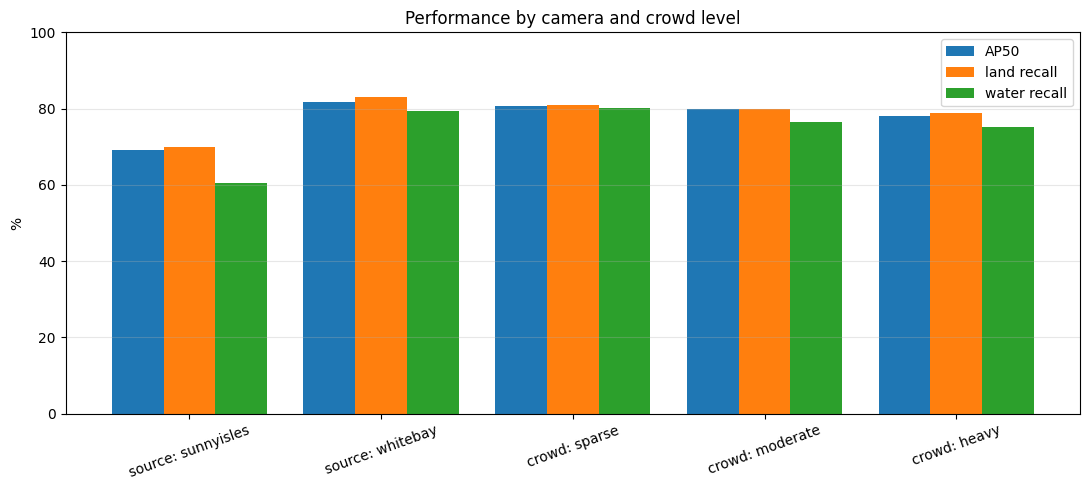

In [13]:
# ---------------- results by scenario: camera source and crowd level (sparse / moderate / heavy) ----------------
meta = {}
mp = [p for p in glob.glob(os.path.join(ROOT, '..', '*meta*.csv')) + glob.glob(os.path.join(ROOT, '*meta*.csv'))]
if mp:
    for r in csv.DictReader(open(mp[0])): meta[r['file_name']] = r.get('crowd_level')
by_id = {d['image_id']: d for d in test_dicts}
gcount = {i: sum(1 for g in gt_boxes[i]) for i in by_id}
src_of = {i: os.path.basename(by_id[i]['file_name']).split('_')[0] for i in by_id}
if not meta:
    for s_ in set(src_of.values()):
        ids = [i for i in by_id if src_of[i] == s_]; v = [gcount[i] for i in ids]; lo, hi = np.percentile(v, 33), np.percentile(v, 66)
        for i in ids: meta[os.path.basename(by_id[i]['file_name'])] = 'sparse' if gcount[i] <= lo else 'moderate' if gcount[i] <= hi else 'heavy'
lvl_of = {i: meta.get(os.path.basename(by_id[i]['file_name']), 'moderate') for i in by_id}
rows = []
def group_row(name, ids):
    if not ids: return
    E = coco_run(img_ids=ids); c_, i_ = confusion(img_ids=ids); s_ = prf(c_, i_)
    pc = {k: sum(int(((preds[i][1] >= SCORE_THR) & (preds[i][2] == k)).sum()) for i in ids) for k in (0, 1)}; gc = {k: sum(1 for i in ids for g in gt_boxes[i] if g[4] == k) for k in (0, 1)}
    rows.append([name, len(ids), round(100 * E.stats[1], 2), round(s_['land']['recall'], 2), round(s_['water']['recall'], 2), round(s_['land']['precision'], 2), round(s_['water']['precision'], 2), gc[0], pc[0], gc[1], pc[1]])
for s_ in sorted(set(src_of.values())): group_row('source: ' + s_, [i for i in by_id if src_of[i] == s_])
for l_ in ('sparse', 'moderate', 'heavy'): group_row('crowd: ' + l_, [i for i in by_id if lvl_of[i] == l_])
hdr = ['group', 'frames', 'AP50', 'land_recall', 'water_recall', 'land_precision', 'water_precision', 'GT_land', 'pred_land', 'GT_water', 'pred_water']
with open(os.path.join(OUT, 'scenario_results.csv'), 'w', newline='') as f: w = csv.writer(f); w.writerow(hdr); w.writerows(rows)
print(' | '.join(hdr))
for r in rows: print(' | '.join(str(x) for x in r))
fig, ax = plt.subplots(figsize=(11, 5)); x = np.arange(len(rows)); wd = 0.27
ax.bar(x - wd, [r[2] for r in rows], wd, label='AP50'); ax.bar(x, [r[3] for r in rows], wd, label='land recall'); ax.bar(x + wd, [r[4] for r in rows], wd, label='water recall')
ax.set_xticks(x); ax.set_xticklabels([r[0] for r in rows], rotation=20); ax.set_ylim(0, 100); ax.set_ylabel('%'); ax.set_title('Performance by camera and crowd level'); ax.legend(); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT, '08_scenario_results.png'), dpi=200); plt.show()

## Algorithms with and without (what mam asked for: "analysis with and without")
Each variant is applied to the **same test frames** and scored with the same metrics, so every difference is measurable.
1. **Baseline** - raw frames.
2. **Denoising** (bilateral filter) - removes sensor / compression noise while keeping edges. Mam said denoising is not a major issue, so this tests that claim.
3. **CLAHE** (contrast-limited adaptive histogram equalisation on the lightness channel) - helps people against glare and bright sand.
4. **Denoise + CLAHE** combined.
5. **NMS tuning** - how strongly overlapping boxes are merged (0.3 / 0.5 / 0.7): matters in crowds.
6. **Transfer learning** - this fine-tuned model vs the original COCO model with no fine-tuning (person boxes assigned land/water by the waterline).

model_final_f6e8b1.pkl: 243MB [00:00, 256MB/s]                           


Loading and preparing results...
DONE (t=0.03s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=8.18s).
Accumulating evaluation results...
DONE (t=0.24s).
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=7.82s).
Accumulating evaluation results...
DONE (t=0.25s).
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=8.17s).
Accumulating evaluation results...
DONE (t=0.25s).
Loading and preparing results...
DONE (t=0.32s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=8.27s).
Accumulating evaluation results...
DONE (t=0.25s).
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t

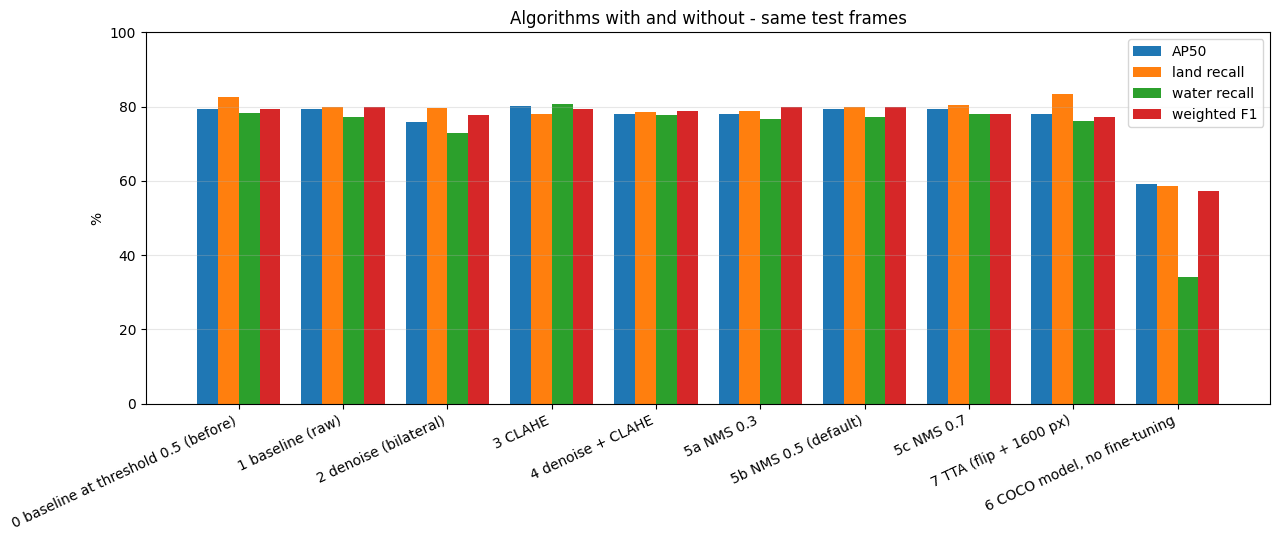

algorithm comparison saved


In [14]:
# ---------------- algorithm comparison ----------------
COL_ = {0: (0, 200, 0), 1: (255, 140, 0)}      # BGR: land = green, water = blue
def denoise(im): return cv2.bilateralFilter(im, 9, 50, 50)
def clahe(im):
    lab = cv2.cvtColor(im, cv2.COLOR_BGR2LAB); l, a, b = cv2.split(lab); l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)
def both(im): return clahe(denoise(im))
def predict_all(fn=None, nms=None):
    if nms is not None: predictor.model.roi_heads.box_predictor.test_nms_thresh = nms
    P = {}
    for d in test_dicts:
        im = cv2.imread(d['file_name']); im = fn(im) if fn else im; inst = predictor(im)['instances'].to('cpu')
        P[d['image_id']] = arrs(inst)
    predictor.model.roi_heads.box_predictor.test_nms_thresh = 0.5
    return P
def score(P, thr=None):
    dl = [{'image_id': i, 'category_id': int(c), 'bbox': [float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])], 'score': float(s)} for i, (bb, ss, cc) in P.items() for b, s, c in zip(bb, ss, cc)]
    ap = 100 * COCOeval_stats(dl)
    cm_, io_ = confusion(P=P) if thr is None else confusion(thr=thr, P=P); st_ = prf(cm_, io_)
    return [round(ap, 2), round(st_['land']['recall'], 2), round(st_['water']['recall'], 2), round(st_['land']['precision'], 2), round(st_['water']['precision'], 2), round(st_['weighted_F1'], 2)]
def COCOeval_stats(dl):
    if not dl: return 0.0
    E = COCOeval(gt, gt.loadRes(dl), 'bbox'); E.evaluate(); E.accumulate()
    with contextlib.redirect_stdout(io.StringIO()): E.summarize()
    return E.stats[1]
variants = [('1 baseline (raw)', predict_all()), ('2 denoise (bilateral)', predict_all(denoise)), ('3 CLAHE', predict_all(clahe)), ('4 denoise + CLAHE', predict_all(both)),
            ('5a NMS 0.3', predict_all(None, 0.3)), ('5b NMS 0.5 (default)', predict_all(None, 0.5)), ('5c NMS 0.7', predict_all(None, 0.7))]
# 7 test-time augmentation (TTA): original + horizontal flip at 1320 px, plus original at 1600 px, merged with NMS
import torch
from torchvision.ops import batched_nms
cfg_big = cfg.clone(); cfg_big.INPUT.MIN_SIZE_TEST = 1600; cfg_big.INPUT.MAX_SIZE_TEST = 2900; pred_big = DefaultPredictor(cfg_big)
P_tta = {}
for d in test_dicts:
    im = cv2.imread(d['file_name']); Wd = im.shape[1]; B, Sc, Cl = [], [], []
    for pr, flip in ((predictor, False), (predictor, True), (pred_big, False)):
        inst = pr(im[:, ::-1].copy() if flip else im)['instances'].to('cpu'); b = inst.pred_boxes.tensor.numpy().copy()
        if flip: b[:, [0, 2]] = Wd - b[:, [2, 0]]
        B.append(b); Sc.append(inst.scores.numpy()); Cl.append(inst.pred_classes.numpy())
    b = torch.tensor(np.concatenate(B)); s = torch.tensor(np.concatenate(Sc)); c = torch.tensor(np.concatenate(Cl))
    k = batched_nms(b, s, c, 0.5).numpy(); b, s, c = b.numpy()[k], s.numpy()[k], c.numpy()[k]; hk = (b[:, 3] - b[:, 1]) >= MIN_H
    P_tta[d['image_id']] = (b[hk], s[hk], c[hk])
variants.append(('7 TTA (flip + 1600 px)', P_tta))
# 6 transfer learning: original COCO detector, no fine-tuning; person -> land/water by waterline (needs waterlines.json from the frames dataset)
wl = [p for p in glob.glob('/kaggle/input/**/waterlines.json', recursive=True)]
if wl:
    import cv2 as _cv
    WL = json.load(open(wl[0])); cfg0 = get_cfg(); cfg0.merge_from_file(model_zoo.get_config_file(CFGFILE)); cfg0.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CFGFILE)
    cfg0.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.05; cfg0.INPUT.MIN_SIZE_TEST = 1320; cfg0.INPUT.MAX_SIZE_TEST = 2400; zs = DefaultPredictor(cfg0); P0 = {}
    def pip(pt, poly):
        x, y = pt; ins = False
        for i in range(len(poly)):
            x1, y1 = poly[i]; x2, y2 = poly[(i + 1) % len(poly)]
            if (y1 > y) != (y2 > y) and x < (x2 - x1) * (y - y1) / (y2 - y1 + 1e-9) + x1: ins = not ins
        return ins
    for d in test_dicts:
        inst = zs(cv2.imread(d['file_name']))['instances'].to('cpu'); k = inst.pred_classes.numpy() == 0; b = inst.pred_boxes.tensor.numpy()[k]; s = inst.scores.numpy()[k]; hk = (b[:, 3] - b[:, 1]) >= MIN_H; b, s = b[hk], s[hk]
        poly = WL.get(os.path.basename(d['file_name']).split('_')[0], {}).get('water_polygon', [])
        c = np.array([1 if poly and pip(((x1 + x2) / 2, y2), poly) else 0 for x1, y1, x2, y2 in b], dtype=int); P0[d['image_id']] = (b, s, c)
    variants.append(('6 COCO model, no fine-tuning', P0))
hdr = ['variant', 'AP50', 'land_recall', 'water_recall', 'land_precision', 'water_precision', 'weighted_F1']
rows_a = [['0 baseline at threshold 0.5 (before)'] + score(variants[0][1], 0.5)] + [[n] + score(P) for n, P in variants]
print('threshold used for recall / precision / F1 in this table:', SCORE_THR)
with open(os.path.join(OUT, 'algorithm_comparison.csv'), 'w', newline='') as f: w = csv.writer(f); w.writerow(hdr); w.writerows(rows_a)
print(' | '.join(hdr))
for r in rows_a: print(' | '.join(str(x) for x in r))
fig, ax = plt.subplots(figsize=(13, 5.5)); x = np.arange(len(rows_a)); wd = 0.2
for k, (lab, col) in enumerate((('AP50', 1), ('land recall', 2), ('water recall', 3), ('weighted F1', 6))): ax.bar(x + (k - 1.5) * wd, [r[col] for r in rows_a], wd, label=lab)
ax.set_xticks(x); ax.set_xticklabels([r[0] for r in rows_a], rotation=25, ha='right'); ax.set_ylim(0, 100); ax.set_ylabel('%'); ax.set_title('Algorithms with and without - same test frames'); ax.legend(); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT, '09_algorithm_comparison.png'), dpi=200); plt.show()
# 3-panel pictures: original | processed | detection output (for the first 3 test frames)
for d in test_dicts[:3]:
    im = cv2.imread(d['file_name']); panels = []
    for lab, fn in (('original', None), ('denoised', denoise), ('CLAHE', clahe)):
        pim = fn(im) if fn else im.copy(); inst = predictor(pim)['instances'].to('cpu'); k = inst.scores.numpy() >= SCORE_THR; out = pim.copy()
        for (x1, y1, x2, y2), c in zip(inst.pred_boxes.tensor.numpy()[k], inst.pred_classes.numpy()[k]): cv2.rectangle(out, (int(x1), int(y1)), (int(x2), int(y2)), COL_[int(c)], 2)
        cv2.putText(out, lab, (20, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (255, 255, 255), 3); panels.append(cv2.resize(np.hstack([pim, out]), None, fx=0.35, fy=0.35))
    cv2.imwrite(os.path.join(OUT, f'10_three_panel_{os.path.basename(d["file_name"])[:-4]}.jpg'), np.vstack(panels))
print('algorithm comparison saved')

sunnyisles {'frames': 199.0, 'GT_land_avg': 5.4, 'pred_land_avg': 5.18, 'GT_water_avg': 4.26, 'pred_water_avg': 3.01, 'MAE_land': 1.02, 'MAE_water': 1.44}
whitebay {'frames': 200.0, 'GT_land_avg': 17.36, 'pred_land_avg': 17.12, 'GT_water_avg': 32.62, 'pred_water_avg': 31.93, 'MAE_land': 1.44, 'MAE_water': 2.63}


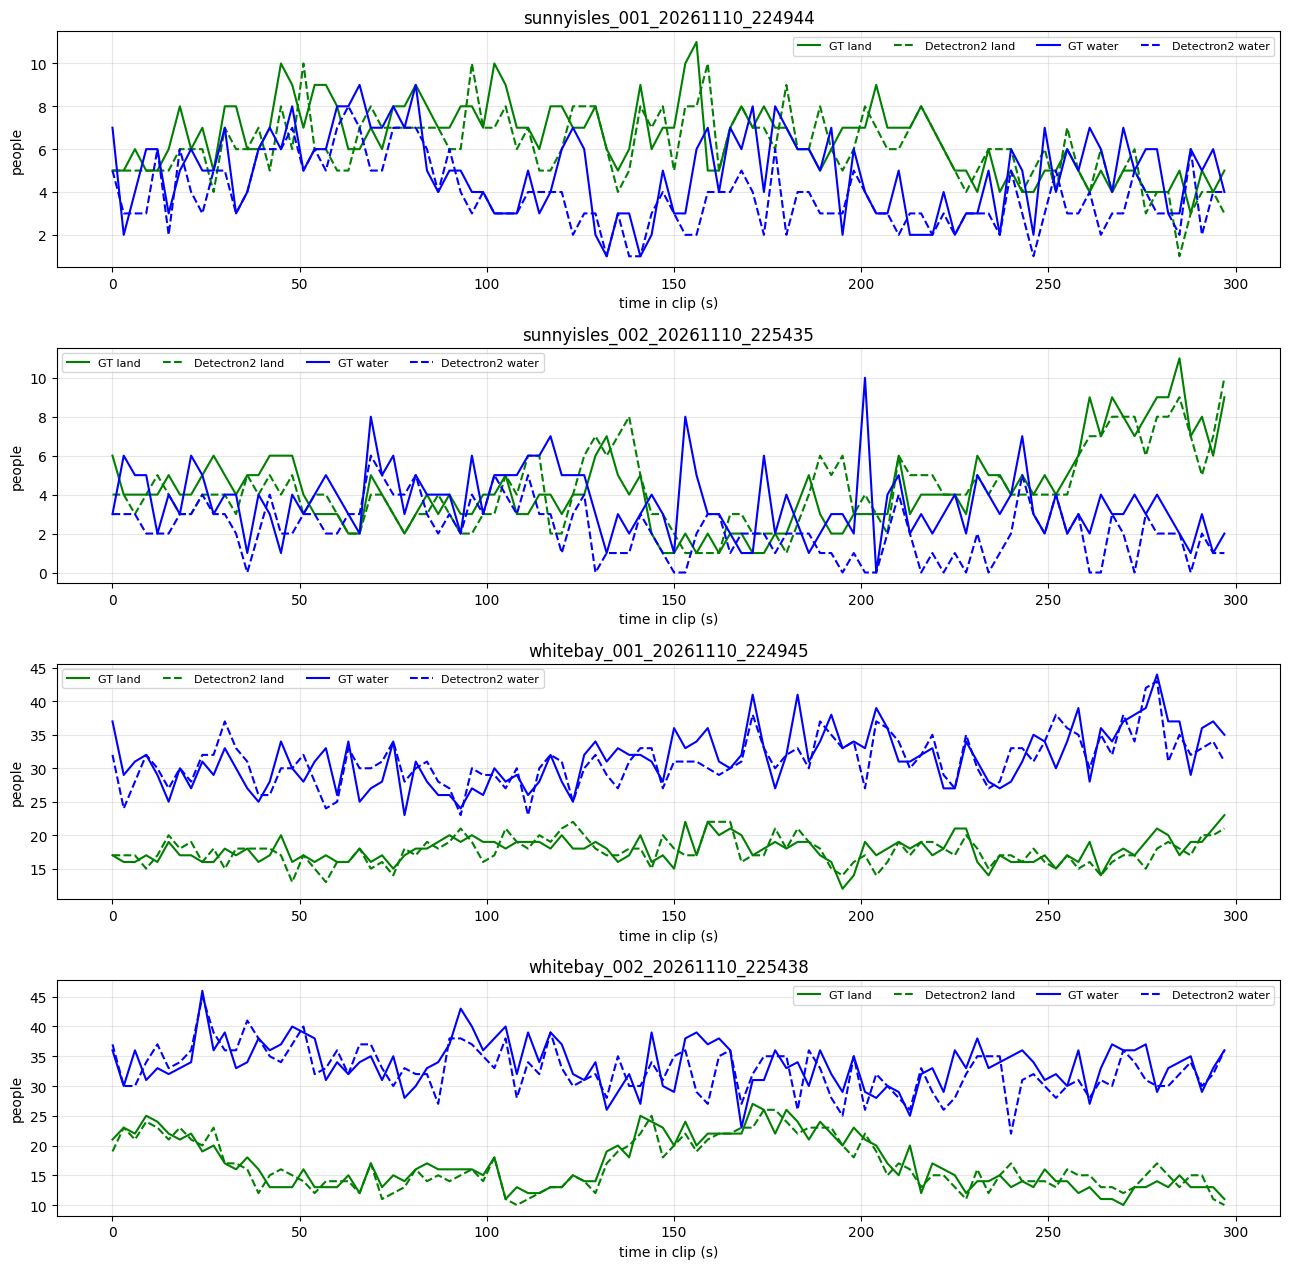

In [15]:
# ---------------- land / water COUNTS per test frame: ground truth vs Detectron2 ----------------
import re
def clip_frame(fn):
    m = re.match(r'(.+?_\d{8}_\d{6})_f(\d+)', os.path.basename(fn)); return (m.group(1), int(m.group(2))) if m else (os.path.basename(fn), 0)
clips = collections.defaultdict(list)
for d in test_dicts: c_, n_ = clip_frame(d['file_name']); clips[c_].append((n_, d))
for c_ in clips: clips[c_].sort(key=lambda t: t[0])
crow = []
for c_, items in sorted(clips.items()):
    for n_, d in items:
        g = gt_boxes[d['image_id']]; b, s, c = preds[d['image_id']]; k = s >= SCORE_THR
        crow.append([c_, n_, (n_ - 1) * 3, sum(1 for x in g if x[4] == 0), sum(1 for x in g if x[4] == 1), int((c[k] == 0).sum()), int((c[k] == 1).sum())])
with open(os.path.join(OUT, 'counts_per_frame.csv'), 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['clip', 'frame', 'time_s', 'GT_land', 'GT_water', 'pred_land', 'pred_water']); w.writerows(crow)
cnt = {}
for bch in sorted(beach_ids):
    r_ = [r for r in crow if r[0].startswith(bch)]
    cnt[bch] = {'frames': len(r_), 'GT_land_avg': np.mean([r[3] for r in r_]), 'pred_land_avg': np.mean([r[5] for r in r_]), 'GT_water_avg': np.mean([r[4] for r in r_]), 'pred_water_avg': np.mean([r[6] for r in r_]),
                'MAE_land': np.mean([abs(r[3] - r[5]) for r in r_]), 'MAE_water': np.mean([abs(r[4] - r[6]) for r in r_])}
    print(bch, {k: round(float(v), 2) for k, v in cnt[bch].items()})
json.dump({b: {k: float(v) for k, v in d.items()} for b, d in cnt.items()}, open(os.path.join(OUT, 'counts_summary.json'), 'w'), indent=2)
fig, ax = plt.subplots(len(clips), 1, figsize=(13, 3.2 * len(clips)), squeeze=False)
for a, (c_, items) in zip(ax[:, 0], sorted(clips.items())):
    r_ = [r for r in crow if r[0] == c_]; t = [r[2] for r in r_]
    a.plot(t, [r[3] for r in r_], 'g-', label='GT land'); a.plot(t, [r[5] for r in r_], 'g--', label='Detectron2 land')
    a.plot(t, [r[4] for r in r_], 'b-', label='GT water'); a.plot(t, [r[6] for r in r_], 'b--', label='Detectron2 water')
    a.set_title(c_); a.set_xlabel('time in clip (s)'); a.set_ylabel('people'); a.grid(alpha=.3); a.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, '11_counts_over_time.png'), dpi=170); plt.show()

In [16]:
# ---------------- VIDEO per test clip: LEFT = ground truth, RIGHT = Detectron2 (land green, water blue, counts on top) ----------------
COL = {0: (0, 200, 0), 1: (255, 140, 0)}      # BGR: land = green, water = blue
import subprocess
def to_h264(p):                                # OpenCV writes mp4v, which browsers/Kaggle cannot play -> re-encode to H.264 (small + plays everywhere)
    t = p[:-4] + '_tmp.mp4'; os.replace(p, t)
    r = subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', t, '-c:v', 'libx264', '-pix_fmt', 'yuv420p', '-crf', '26', '-preset', 'veryfast', '-movflags', '+faststart', p])
    if r.returncode == 0: os.remove(t)
    else: os.replace(t, p); print('ffmpeg failed, kept mp4v version (plays in VLC):', p)
def panel(im, boxes, classes, title, scale=1280):
    h, w = im.shape[:2]; f = scale / w; im = cv2.resize(im, (scale, int(h * f)))
    n = {0: 0, 1: 0}
    for (x1, y1, x2, y2), c in zip(boxes, classes):
        n[int(c)] += 1; cv2.rectangle(im, (int(x1 * f), int(y1 * f)), (int(x2 * f), int(y2 * f)), COL[int(c)], 2)
    txt = f'{title}   Land: {n[0]}  |  Water: {n[1]}'; (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.9, 2)
    cv2.rectangle(im, (0, 0), (tw + 24, th + 22), (0, 0, 0), -1); cv2.putText(im, txt, (12, th + 8), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2, cv2.LINE_AA)
    return im
allw = None
for c_, items in sorted(clips.items()):
    vw = None
    for n_, d in items:
        im = cv2.imread(d['file_name']); g = gt_boxes[d['image_id']]; b, s, c = preds[d['image_id']]; k = s >= SCORE_THR
        frame = np.hstack([panel(im.copy(), [x[:4] for x in g], [x[4] for x in g], 'Ground truth'), panel(im.copy(), b[k], c[k], 'Detectron2')])
        cv2.putText(frame, f'{c_}  frame {n_}  (t = {(n_ - 1) * 3} s)', (12, frame.shape[0] - 14), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
        if vw is None: vw = cv2.VideoWriter(os.path.join(OUT, f'video_GT_vs_Detectron2_{c_}.mp4'), cv2.VideoWriter_fourcc(*'mp4v'), VIDEO_FPS, (frame.shape[1], frame.shape[0]))
        if allw is None: allw = cv2.VideoWriter(os.path.join(OUT, 'video_GT_vs_Detectron2_ALL_test_clips.mp4'), cv2.VideoWriter_fourcc(*'mp4v'), VIDEO_FPS, (frame.shape[1], frame.shape[0]))
        vw.write(frame); allw.write(frame)
    vw.release(); to_h264(os.path.join(OUT, f'video_GT_vs_Detectron2_{c_}.mp4')); print('saved video_GT_vs_Detectron2_%s.mp4 (%d frames)' % (c_, len(items)))
allw.release(); to_h264(os.path.join(OUT, 'video_GT_vs_Detectron2_ALL_test_clips.mp4'))
# still pictures for the report / slides: the 3 most crowded test frames of each beach, GT left vs Detectron2 right
for bch in sorted(beach_ids):
    top = sorted([d for d in test_dicts if beach_of(d['file_name']) == bch], key=lambda d: -len(gt_boxes[d['image_id']]))[:3]
    for j, d in enumerate(top):
        im = cv2.imread(d['file_name']); g = gt_boxes[d['image_id']]; b, s, c = preds[d['image_id']]; k = s >= SCORE_THR
        cv2.imwrite(os.path.join(OUT, f'12_sample_{bch}_{j + 1}_GT_vs_Detectron2.jpg'),
                    np.hstack([panel(im.copy(), [x[:4] for x in g], [x[4] for x in g], 'Ground truth'), panel(im.copy(), b[k], c[k], 'Detectron2')]))
print('sample pictures saved (12_sample_*.jpg)')

saved video_GT_vs_Detectron2_sunnyisles_001_20261110_224944.mp4 (100 frames)
saved video_GT_vs_Detectron2_sunnyisles_002_20261110_225435.mp4 (99 frames)
saved video_GT_vs_Detectron2_whitebay_001_20261110_224945.mp4 (100 frames)
saved video_GT_vs_Detectron2_whitebay_002_20261110_225438.mp4 (100 frames)
sample pictures saved (12_sample_*.jpg)


In [17]:
# ---------------- CONTINUOUS real-speed video of each test clip (needs the clip videos attached as an input) ----------------
VID = {}
for dp, dn, fn in os.walk('/kaggle/input'):
    for f in fn:
        if f.lower().endswith(('.mkv', '.mp4', '.avi', '.mov')): VID[os.path.splitext(f)[0]] = os.path.join(dp, f)
cont = []
for c_ in sorted(clips):
    if c_ not in VID: print('no video file for', c_, '-> skipped (attach the clip videos to make this)'); continue
    bch = c_.split('_')[0]; cap = cv2.VideoCapture(VID[c_]); fps = cap.get(cv2.CAP_PROP_FPS) or 25
    nmax = int(CONT_SECONDS * fps) if CONT_SECONDS else int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); vw = None; last = (np.zeros((0, 4)), np.zeros(0)); i = 0
    while i < nmax:
        ok, im = cap.read()
        if not ok: break
        if im.shape[1] != 1920: im = cv2.resize(im, (1920, 1080))
        for x, y, w, h in MASKS.get(bch, []): im[y:y + h, x:x + w] = 0              # same masking as the training frames
        if i % CONT_STRIDE == 0:
            b, s, c = arrs(predictor(im)['instances'].to('cpu')); k = s >= SCORE_THR; last = (b[k], c[k])
            cont.append([c_, round(i / fps, 2), int((last[1] == 0).sum()), int((last[1] == 1).sum())])
        out = panel(im, last[0], last[1], 'Detectron2 (real speed)')
        if vw is None: vw = cv2.VideoWriter(os.path.join(OUT, f'video_continuous_{c_}.mp4'), cv2.VideoWriter_fourcc(*'mp4v'), fps, (out.shape[1], out.shape[0]))
        vw.write(out); i += 1
    vw.release(); cap.release(); to_h264(os.path.join(OUT, f'video_continuous_{c_}.mp4')); print('saved video_continuous_%s.mp4: %d frames at %.1f fps' % (c_, i, fps))
if cont:
    with open(os.path.join(OUT, 'counts_continuous.csv'), 'w', newline='') as f:
        w = csv.writer(f); w.writerow(['clip', 'time_s', 'pred_land', 'pred_water']); w.writerows(cont)

saved video_continuous_sunnyisles_001_20261110_224944.mp4: 3750 frames at 62.5 fps
saved video_continuous_sunnyisles_002_20261110_225435.mp4: 3750 frames at 62.5 fps
saved video_continuous_whitebay_001_20261110_224945.mp4: 1818 frames at 30.3 fps
saved video_continuous_whitebay_002_20261110_225438.mp4: 1818 frames at 30.3 fps


In [18]:
# ---------------- package + final summary ----------------
shutil.copy2(os.path.join(cfg.OUTPUT_DIR, 'metrics.json'), os.path.join(OUT, 'training_metrics.jsonl'))
zp = '/kaggle/working/G110_Detectron2_Results.zip'                 # small zip: everything EXCEPT videos (download videos one by one)
with zipfile.ZipFile(zp, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in glob.glob(os.path.join(OUT, '*')):
        if os.path.isfile(p) and not p.endswith('.mp4'): z.write(p, os.path.basename(p))
for p in sorted(glob.glob(os.path.join(cfg.OUTPUT_DIR, '*.pth'))):  # keep only model_best.pth -> output stays small
    if os.path.basename(p) != 'model_best.pth': os.remove(p)
for d_ in ['/kaggle/working/coco_fixed', '/kaggle/working/coco_from_yolo'] + glob.glob('/kaggle/working/G110-Beach-People-Final-*') + glob.glob('/kaggle/working/rf_v*'):
    shutil.rmtree(d_, ignore_errors=True)                           # dataset copies are not results -> remove so the Output tab stays small
for p in sorted(glob.glob('/kaggle/working/**/*', recursive=True)):
    if os.path.isfile(p) and os.path.getsize(p) > 20e6: print('big file: %-70s %6.0f MB' % (p, os.path.getsize(p) / 1e6))
print('Dataset: Roboflow', RF_PROJECT, 'v%d' % RF_VERSION, '| weights used:', os.path.basename(cfg.MODEL.WEIGHTS))
print('mAP@50: %.2f%% | mAP@50:95: %.2f%% | speed: %.2f frames/s' % (res['mAP@50'], res['mAP@50:95'], FPS_MODEL))
print('AP50 land: %.2f%% | AP50 water: %.2f%%' % (res['AP50 land'], res['AP50 water']))
print('Recall land: %.2f%% | Recall water: %.2f%%' % (stats['land']['recall'], stats['water']['recall']))
for bch in sorted(beach_ids): print('%-10s mAP@50: %.2f%% | count error per frame (MAE) land %.2f, water %.2f' % (bch, res[bch + ' mAP@50'], cnt[bch]['MAE_land'], cnt[bch]['MAE_water']))
print('All outputs zipped ->', zp)

big file: /kaggle/working/outputs/d2/model_best.pth                                 482 MB
big file: /kaggle/working/outputs/video_GT_vs_Detectron2_ALL_test_clips.mp4          48 MB
Dataset: Roboflow g110-beach-people-final v2 | weights used: model_best.pth
mAP@50: 79.24% | mAP@50:95: 41.87% | speed: 1.30 frames/s
AP50 land: 83.89% | AP50 water: 74.59%
Recall land: 79.85% | Recall water: 77.22%
sunnyisles mAP@50: 69.16% | count error per frame (MAE) land 1.02, water 1.44
whitebay   mAP@50: 81.78% | count error per frame (MAE) land 1.44, water 2.63
All outputs zipped -> /kaggle/working/G110_Detectron2_Results.zip
